In [25]:
import json
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "results").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate the project root containing results/")
    PROJECT_ROOT = PROJECT_ROOT.parent


def load_results(file_name):
    path = PROJECT_ROOT / "results" / file_name

    if not path.exists():
        return None

    with path.open("r", encoding="utf-8") as file:
        return json.load(file)


conv1d_results = load_results(
    "conv1d_fsl_results.json"
)
gasf_results = load_results(
    "gasf_fsl_results.json"
)
gadf_results = load_results(
    "gadf_fsl_results.json"
)


def metric(results, shot, name):
    if results is None:
        return "Pending"
    return results[shot][name]


results_table = pd.DataFrame({
    "Representation": [
        "Normalized 1D",
        "GASF",
        "GADF"
    ],
    "1-shot Accuracy": [
        metric(conv1d_results, "1_shot", "accuracy"),
        metric(gasf_results, "1_shot", "accuracy"),
        metric(gadf_results, "1_shot", "accuracy")
    ],
    "1-shot F1": [
        metric(conv1d_results, "1_shot", "f1"),
        metric(gasf_results, "1_shot", "f1"),
        metric(gadf_results, "1_shot", "f1")
    ],
    "1-shot AUC": [
        metric(conv1d_results, "1_shot", "auc"),
        metric(gasf_results, "1_shot", "auc"),
        metric(gadf_results, "1_shot", "auc")
    ],
    "5-shot Accuracy": [
        metric(conv1d_results, "5_shot", "accuracy"),
        metric(gasf_results, "5_shot", "accuracy"),
        metric(gadf_results, "5_shot", "accuracy")
    ],
    "5-shot F1": [
        metric(conv1d_results, "5_shot", "f1"),
        metric(gasf_results, "5_shot", "f1"),
        metric(gadf_results, "5_shot", "f1")
    ],
    "5-shot AUC": [
        metric(conv1d_results, "5_shot", "auc"),
        metric(gasf_results, "5_shot", "auc"),
        metric(gadf_results, "5_shot", "auc")
    ]
})

results_table

,Representation,1-shot Accuracy,1-shot F1,1-shot AUC,5-shot Accuracy,5-shot F1,5-shot AUC
0,Normalized 1D,1.000,1.000000,1.000000,1.000000,1.000000,1.000000
1,GASF,0.350,0.330601,0.512503,0.360667,0.357853,0.525497
2,GADF,0.464,0.467046,0.654311,0.518667,0.519149,0.727201


In [26]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [27]:
print("===== Conv1D =====")
print(conv1d_results.keys())

print("\n===== GASF =====")
print(gasf_results.keys())

print("\n===== GADF =====")
print(gadf_results.keys())

print("\n===== Conv1D 1-shot =====")
print(conv1d_results["1_shot"].keys())

print("\n===== GASF 1-shot =====")
print(gasf_results["1_shot"].keys())

print("\n===== GADF 1-shot =====")
print(gadf_results["1_shot"].keys())

===== Conv1D =====
dict_keys(['representation', 'model', '1_shot', '5_shot'])

===== GASF =====
dict_keys(['representation', 'model', '1_shot', '5_shot'])

===== GADF =====
dict_keys(['representation', 'model', '1_shot', '5_shot'])

===== Conv1D 1-shot =====
dict_keys(['accuracy', 'f1', 'auc'])

===== GASF 1-shot =====
dict_keys(['accuracy', 'f1', 'auc'])

===== GADF 1-shot =====
dict_keys(['accuracy', 'f1', 'auc'])


In [28]:
# Check the saved model metadata

print("===== Conv1D =====")
print(conv1d_results["model"])

print("\n===== GASF =====")
print(gasf_results["model"])

print("\n===== GADF =====")
print(gadf_results["model"])

===== Conv1D =====
Siamese Conv1D

===== GASF =====
Siamese Conv2D

===== GADF =====
Siamese Conv2D


In [29]:
import importlib

import src.fsl as fsl
import src.image_fsl as image_fsl

fsl = importlib.reload(fsl)
image_fsl = importlib.reload(image_fsl)

from src.fsl import (
    create_episode,
    compute_prototypes,
    classify_queries,
    get_embeddings,
)

get_image_embeddings = image_fsl.get_image_embeddings

print("Few-shot modules reloaded and evaluation imports resolved")

Few-shot modules reloaded and evaluation imports resolved


In [30]:
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score
from pathlib import Path

from src.models import SiameseNetwork, Siamese2D
from src.fsl import (
    create_episode,
    compute_prototypes,
    classify_queries,
    get_embeddings,
)
from src.image_fsl import get_image_embeddings


# ============================================================
# 1. General configuration
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

CLASS_NAMES = ["normal", "irf", "orf"]

N_EPISODES = 100
QUERY_PER_CLASS = 5

IMAGE_ROOT = PROJECT_ROOT / "datasets" / "images"
MODEL_DIR = PROJECT_ROOT / "models"

PREDICTION_DIR = PROJECT_ROOT / "results" / "predictions"
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. Load the fixed split
# ============================================================

split = np.load(
    PROJECT_ROOT / "results" / "fsl_split.npz"
)

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]

print("Test samples:", len(test_idx))


# ============================================================
# 3. Load normalized 1D data
# ============================================================

NORMALIZED_DIR = PROJECT_ROOT / "datasets" / "normalized"

X_list = []
y_list = []

for label, class_name in enumerate(CLASS_NAMES):

    X_class = np.loadtxt(
        NORMALIZED_DIR / f"{class_name}.csv",
        delimiter=","
    ).astype(np.float32)

    X_list.append(X_class)
    y_list.extend(
        [label] * len(X_class)
    )

X = np.concatenate(
    X_list,
    axis=0
)

y = np.asarray(
    y_list,
    dtype=np.int64
)

print("X shape:", X.shape)
print("y shape:", y.shape)


# ============================================================
# 4. Load models
# ============================================================

conv1d_model = SiameseNetwork(
    embedding_dim=128
).to(DEVICE)

gasf_model = Siamese2D(
    embedding_dim=128
).to(DEVICE)

gadf_model = Siamese2D(
    embedding_dim=128
).to(DEVICE)


def load_checkpoint(model, filename):

    checkpoint = torch.load(
        MODEL_DIR / filename,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    return model


conv1d_model = load_checkpoint(
    conv1d_model,
    "fsl_conv1d_best.pt"
)

gasf_model = load_checkpoint(
    gasf_model,
    "fsl_gasf_best.pt"
)

gadf_model = load_checkpoint(
    gadf_model,
    "fsl_gadf_best.pt"
)

print("All three models loaded successfully.")


# ============================================================
# 5. Convert distances to probabilities
# ============================================================

def distances_to_probabilities(distances):

    logits = -distances

    logits = (
        logits
        - logits.max(
            axis=1,
            keepdims=True
        )
    )

    exp_logits = np.exp(logits)

    return (
        exp_logits
        / exp_logits.sum(
            axis=1,
            keepdims=True
        )
    )


# ============================================================
# 6. Evaluate one model
# ============================================================

def evaluate_model(
    model,
    representation,
    k_shot
):

    all_true = []
    all_pred = []
    all_probabilities = []

    episode_accuracies = []
    episode_f1s = []

    rng = np.random.default_rng(42)

    for episode_number in range(N_EPISODES):

        episode = create_episode(
            indices=test_idx,
            labels=y,
            n_way=3,
            k_shot=k_shot,
            query_per_class=QUERY_PER_CLASS,
            rng=rng
        )

        # ----------------------------------------------------
        # Extract support/query embeddings
        # ----------------------------------------------------

        if representation == "normalized_1d":

            support_embeddings = get_embeddings(
                model,
                X,
                episode.support_indices,
                DEVICE
            )

            query_embeddings = get_embeddings(
                model,
                X,
                episode.query_indices,
                DEVICE
            )

        else:

            support_embeddings = get_image_embeddings(
                model=model,
                image_root=IMAGE_ROOT,
                indices=episode.support_indices,
                labels=y,
                class_names=CLASS_NAMES,
                representation=representation,
                device=DEVICE,
                batch_size=16
            )

            query_embeddings = get_image_embeddings(
                model=model,
                image_root=IMAGE_ROOT,
                indices=episode.query_indices,
                labels=y,
                class_names=CLASS_NAMES,
                representation=representation,
                device=DEVICE,
                batch_size=16
            )

        # ----------------------------------------------------
        # Build class prototypes
        # ----------------------------------------------------

        prototypes = compute_prototypes(
            support_embeddings,
            episode.support_labels
        )

        # ----------------------------------------------------
        # Classify query samples
        # ----------------------------------------------------

        predictions, distances = classify_queries(
            query_embeddings,
            prototypes
        )

        probabilities = distances_to_probabilities(
            distances
        )

        y_true_episode = episode.query_labels

        accuracy = accuracy_score(
            y_true_episode,
            predictions
        )

        f1 = f1_score(
            y_true_episode,
            predictions,
            average="macro"
        )

        episode_accuracies.append(
            accuracy
        )

        episode_f1s.append(
            f1
        )

        all_true.extend(
            y_true_episode.tolist()
        )

        all_pred.extend(
            predictions.tolist()
        )

        all_probabilities.append(
            probabilities
        )

    # --------------------------------------------------------
    # Convert to arrays
    # --------------------------------------------------------

    all_true = np.asarray(
        all_true,
        dtype=np.int64
    )

    all_pred = np.asarray(
        all_pred,
        dtype=np.int64
    )

    all_probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )

    return {
        "y_true": all_true,
        "y_pred": all_pred,
        "probabilities": all_probabilities,
        "episode_accuracy": np.asarray(
            episode_accuracies
        ),
        "episode_f1": np.asarray(
            episode_f1s
        )
    }


# ============================================================
# 7. Run all six evaluations
# ============================================================

evaluations = {}

for representation, model in [
    ("normalized_1d", conv1d_model),
    ("gasf", gasf_model),
    ("gadf", gadf_model)
]:

    for k_shot in [1, 5]:

        print(
            f"\nEvaluating "
            f"{representation} — {k_shot}-shot..."
        )

        key = f"{representation}_{k_shot}shot"

        evaluations[key] = evaluate_model(
            model=model,
            representation=representation,
            k_shot=k_shot
        )

        result = evaluations[key]

        print(
            "Accuracy:",
            accuracy_score(
                result["y_true"],
                result["y_pred"]
            )
        )

        print(
            "F1:",
            f1_score(
                result["y_true"],
                result["y_pred"],
                average="macro"
            )
        )


# ============================================================
# 8. Save predictions
# ============================================================

for key, result in evaluations.items():

    np.savez(
        PREDICTION_DIR / f"{key}.npz",
        y_true=result["y_true"],
        y_pred=result["y_pred"],
        probabilities=result["probabilities"],
        episode_accuracy=result["episode_accuracy"],
        episode_f1=result["episode_f1"]
    )

print("\nPrediction files saved to:")
print(PREDICTION_DIR)

Device: cpu
Test samples: 45
X shape: (300, 100000)
y shape: (300,)
All three models loaded successfully.

Evaluating normalized_1d — 1-shot...
Accuracy: 1.0
F1: 1.0

Evaluating normalized_1d — 5-shot...
Accuracy: 1.0
F1: 1.0

Evaluating gasf — 1-shot...
Accuracy: 0.35
F1: 0.33060062822773073

Evaluating gasf — 5-shot...
Accuracy: 0.3606666666666667
F1: 0.3578526350893378

Evaluating gadf — 1-shot...
Accuracy: 0.464
F1: 0.4670463801184277

Evaluating gadf — 5-shot...
Accuracy: 0.5186666666666667
F1: 0.5191492007426234

Prediction files saved to:
c:\Users\asus\OneDrive\Desktop\siamese-network\results\predictions


normalized_1d_1shot: 1500 predictions loaded
normalized_1d_5shot: 1500 predictions loaded
gasf_1shot: 1500 predictions loaded
gasf_5shot: 1500 predictions loaded
gadf_1shot: 1500 predictions loaded
gadf_5shot: 1500 predictions loaded


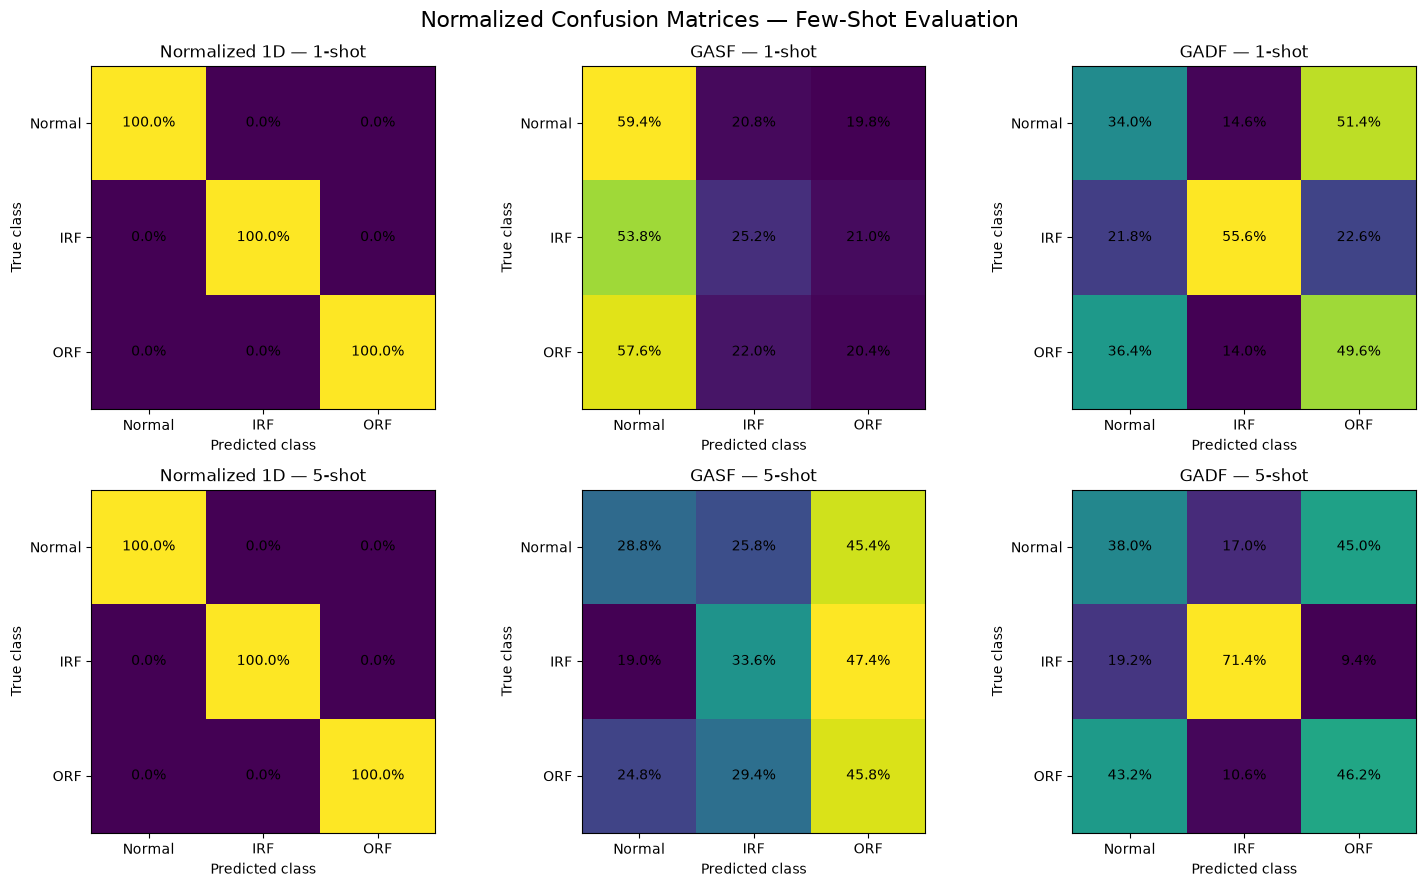

Saved:
c:\Users\asus\OneDrive\Desktop\siamese-network\results\figures\confusion_matrices_fsl.png


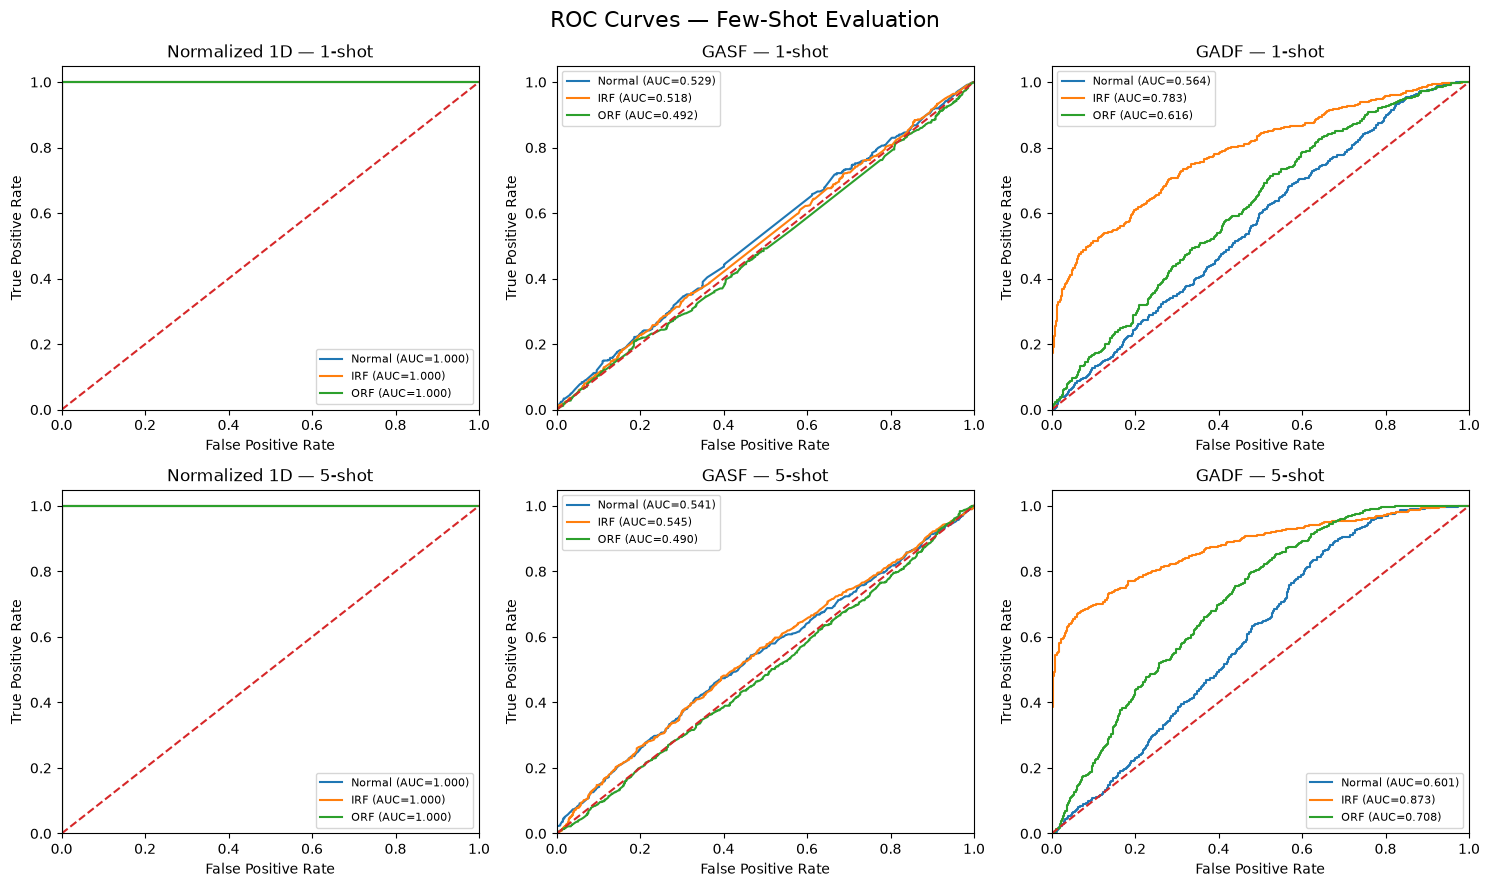

Saved:
c:\Users\asus\OneDrive\Desktop\siamese-network\results\figures\roc_curves_fsl.png


: 

In [ ]:
# ============================================================
# NOTEBOOK CELL
# Final evaluation: confusion matrices + ROC curves
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
)
from sklearn.preprocessing import label_binarize


FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PREDICTION_DIR = PROJECT_ROOT / "results" / "predictions"

CLASS_NAMES = ["Normal", "IRF", "ORF"]
CLASS_IDS = np.arange(len(CLASS_NAMES))

EXPERIMENTS = [
    ("normalized_1d", "Normalized 1D"),
    ("gasf", "GASF"),
    ("gadf", "GADF"),
]


# ------------------------------------------------------------
# Load saved predictions
# ------------------------------------------------------------

predictions = {}

for representation, display_name in EXPERIMENTS:
    for k_shot in [1, 5]:

        key = f"{representation}_{k_shot}shot"
        path = PREDICTION_DIR / f"{key}.npz"

        data = np.load(path)

        predictions[key] = {
            "y_true": data["y_true"],
            "y_pred": data["y_pred"],
            "probabilities": data["probabilities"],
        }

        print(
            f"{key}: "
            f"{len(data['y_true'])} predictions loaded"
        )


# ============================================================
# 1. CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

for col, (representation, display_name) in enumerate(EXPERIMENTS):

    for row, k_shot in enumerate([1, 5]):

        key = f"{representation}_{k_shot}shot"

        y_true = predictions[key]["y_true"]
        y_pred = predictions[key]["y_pred"]

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=CLASS_IDS,
            normalize="true"
        )

        ax = axes[row, col]

        image = ax.imshow(cm)

        ax.set_title(
            f"{display_name} — {k_shot}-shot"
        )

        ax.set_xlabel("Predicted class")
        ax.set_ylabel("True class")

        ax.set_xticks(CLASS_IDS)
        ax.set_yticks(CLASS_IDS)

        ax.set_xticklabels(CLASS_NAMES)
        ax.set_yticklabels(CLASS_NAMES)

        # Write percentages inside the matrix
        for i in range(len(CLASS_NAMES)):
            for j in range(len(CLASS_NAMES)):
                ax.text(
                    j,
                    i,
                    f"{cm[i, j] * 100:.1f}%",
                    ha="center",
                    va="center"
                )

fig.suptitle(
    "Normalized Confusion Matrices — Few-Shot Evaluation",
    fontsize=16
)

fig.tight_layout()

confusion_path = (
    FIGURES_DIR / "confusion_matrices_fsl.png"
)

fig.savefig(
    confusion_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(confusion_path)


# ============================================================
# 2. ROC CURVES
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

for col, (representation, display_name) in enumerate(EXPERIMENTS):

    for row, k_shot in enumerate([1, 5]):

        key = f"{representation}_{k_shot}shot"

        y_true = predictions[key]["y_true"]
        probabilities = predictions[key]["probabilities"]

        # Convert labels to one-vs-rest representation
        y_true_binary = label_binarize(
            y_true,
            classes=CLASS_IDS
        )

        ax = axes[row, col]

        for class_id, class_name in enumerate(CLASS_NAMES):

            fpr, tpr, _ = roc_curve(
                y_true_binary[:, class_id],
                probabilities[:, class_id]
            )

            roc_auc = auc(fpr, tpr)

            ax.plot(
                fpr,
                tpr,
                label=f"{class_name} (AUC={roc_auc:.3f})"
            )

        # Random classifier reference
        ax.plot(
            [0, 1],
            [0, 1],
            linestyle="--"
        )

        ax.set_title(
            f"{display_name} — {k_shot}-shot"
        )

        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.05)

        ax.legend(fontsize=8)

fig.suptitle(
    "ROC Curves — Few-Shot Evaluation",
    fontsize=16
)

fig.tight_layout()

roc_path = FIGURES_DIR / "roc_curves_fsl.png"

fig.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(roc_path)

In [6]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "results").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate the project root containing results/")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import torch
import json
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)

from src.models import SiameseNetwork, Siamese2D
from src.fsl import create_episode, get_embeddings, compute_prototypes, classify_queries
from src.image_fsl import get_image_embeddings

In [2]:
split = np.load("../results/fsl_split.npz")

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]
y = split["y"]

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

print("Test class distribution:")
print(np.bincount(y[test_idx]))

Train: 210
Validation: 45
Test: 45
Test class distribution:
[15 15 15]


In [8]:
CLASS_NAMES = ["normal", "irf", "orf"]

N_WAY = 3
QUERY_PER_CLASS = 5
N_EPISODES = 100

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [9]:
def evaluate_fsl_predictions(
    model,
    X,
    test_idx,
    y,
    k_shot,
    n_episodes=100,
    query_per_class=5,
    device="cpu"
):

    rng = np.random.default_rng(42 + k_shot)

    all_true = []
    all_pred = []
    all_distances = []

    for episode_number in range(n_episodes):

        episode = create_episode(
            indices=test_idx,
            labels=y,
            n_way=3,
            k_shot=k_shot,
            query_per_class=query_per_class,
            rng=rng
        )

        support_embeddings = get_embeddings(
            model,
            X,
            episode.support_indices,
            device
        )

        query_embeddings = get_embeddings(
            model,
            X,
            episode.query_indices,
            device
        )

        prototypes = compute_prototypes(
            support_embeddings,
            episode.support_labels
        )

        predictions, distances = classify_queries(
            query_embeddings,
            prototypes
        )

        all_true.extend(episode.query_labels)
        all_pred.extend(predictions)
        all_distances.extend(distances)

    all_true = np.asarray(all_true)
    all_pred = np.asarray(all_pred)
    all_distances = np.asarray(all_distances)

    accuracy = accuracy_score(
        all_true,
        all_pred
    )

    f1 = f1_score(
        all_true,
        all_pred,
        average="macro"
    )

    cm = confusion_matrix(
        all_true,
        all_pred,
        labels=[0, 1, 2]
    )

    return {
        "y_true": all_true,
        "y_pred": all_pred,
        "distances": all_distances,
        "accuracy": accuracy,
        "f1": f1,
        "confusion_matrix": cm
    }

In [10]:
gasf_model = Siamese2D(
    embedding_dim=128
).to(device)

checkpoint = torch.load(
    "../models/fsl_gasf_512_best.pt",
    map_location=device
)

gasf_model.load_state_dict(
    checkpoint["model_state_dict"]
)

gasf_model.eval()

print("GASF 512 model loaded.")

GASF 512 model loaded.


In [15]:
prediction_path = PROJECT_ROOT / "results" / "predictions" / "gasf_512_1shot.npz"

with np.load(prediction_path) as prediction_data:
    y_true = prediction_data["y_true"]
    probabilities = prediction_data["probabilities"]

roc_auc = roc_auc_score(
    y_true,
    probabilities,
    multi_class="ovr",
    average="macro"
)

print("GASF 512 1-shot macro ROC-AUC:", roc_auc)

GASF 512 1-shot macro ROC-AUC: 0.5215279999999999


In [19]:
with np.load(prediction_path) as prediction_data:
    y_true = prediction_data["y_true"]
    y_pred = prediction_data["y_pred"]

y_true, y_pred

(array([0, 0, 0, ..., 2, 2, 2], shape=(1500,)),
 array([2, 2, 2, ..., 1, 1, 1], shape=(1500,)))

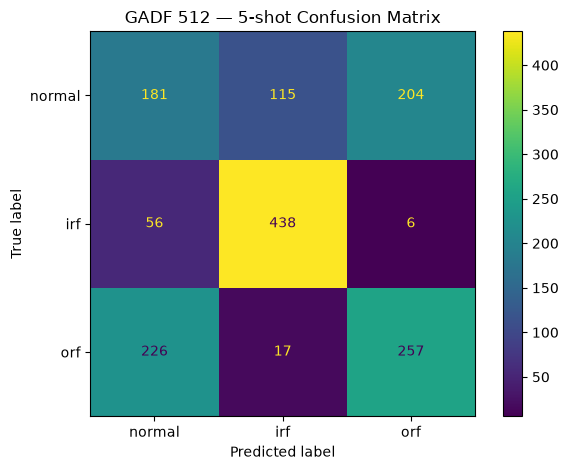

In [22]:
prediction_path = PROJECT_ROOT / "results" / "predictions" / "gadf_512_5shot.npz"

with np.load(prediction_path) as prediction_data:
    y_true = prediction_data["y_true"]
    y_pred = prediction_data["y_pred"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(CLASS_NAMES))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot()
plt.title("GADF 512 — 5-shot Confusion Matrix")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

CLASS_NAMES = ["normal", "irf", "orf"]
CLASS_IDS = [0, 1, 2]


def compute_multiclass_roc(result):
    """
    Compute one-vs-rest ROC curves from prototype distances.

    Smaller distance = more similar.
    Therefore we use -distance as the class score.
    """

    y_true = result["y_true"]
    distances = result["distances"]

    # Convert labels to one-hot representation
    y_true_bin = label_binarize(
        y_true,
        classes=CLASS_IDS
    )

    # Prototype distance -> similarity score
    scores = -distances

    fpr = {}
    tpr = {}
    roc_auc = {}

    for i, class_name in enumerate(CLASS_NAMES):

        fpr[i], tpr[i], _ = roc_curve(
            y_true_bin[:, i],
            scores[:, i]
        )

        roc_auc[i] = auc(
            fpr[i],
            tpr[i]
        )

    macro_auc = roc_auc_score(
        y_true_bin,
        scores,
        average="macro",
        multi_class="ovr"
    )

    return fpr, tpr, roc_auc, macro_auc

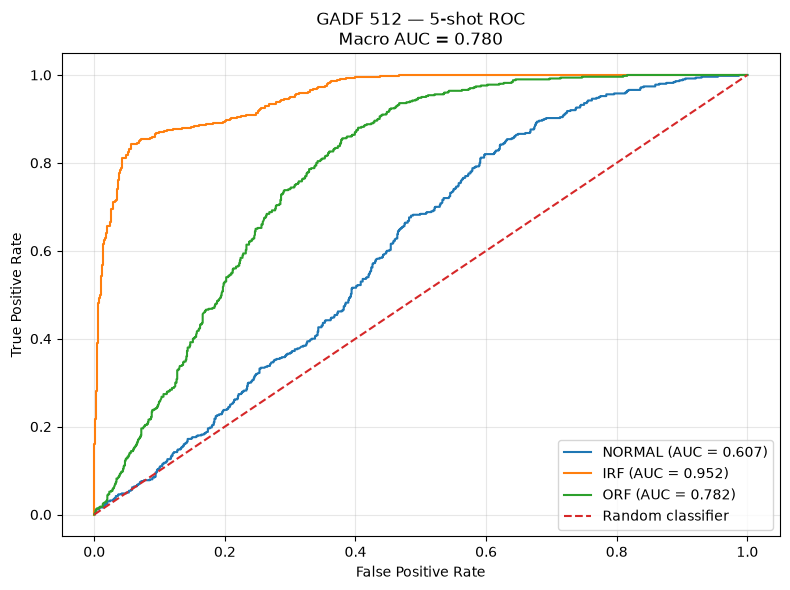

Per-class AUC:
NORMAL: 0.6074
IRF: 0.9518
ORF: 0.7816

Macro AUC: 0.7803


In [25]:
import matplotlib.pyplot as plt

prediction_path = PROJECT_ROOT / "results" / "predictions" / "gadf_512_5shot.npz"

with np.load(prediction_path) as prediction_data:
    result = {
        "y_true": prediction_data["y_true"],
        "distances": -prediction_data["probabilities"]
    }

fpr, tpr, roc_auc, macro_auc = compute_multiclass_roc(
    result
)

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(CLASS_NAMES):

    plt.plot(
        fpr[i],
        tpr[i],
        label=f"{class_name.upper()} (AUC = {roc_auc[i]:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"GADF 512 — 5-shot ROC\nMacro AUC = {macro_auc:.3f}"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Per-class AUC:")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name.upper()}: "
        f"{roc_auc[i]:.4f}"
    )

print(f"\nMacro AUC: {macro_auc:.4f}")

In [26]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize

sys.path.append("../src")

from models import SiameseNetwork
from fsl import (
    create_episode,
    get_embeddings,
    compute_prototypes,
    classify_queries
)

print("Imports OK")

Imports OK


In [27]:
PROJECT_ROOT = Path("..")

RESULT_ROOT = PROJECT_ROOT / "results"
MODEL_ROOT = PROJECT_ROOT / "models"

FIGURE_ROOT = (
    RESULT_ROOT
    / "figures"
    / "final"
)

FIGURE_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

CLASS_NAMES = [
    "normal",
    "irf",
    "orf"
]

CLASS_IDS = [0, 1, 2]

N_WAY = 3
N_EPISODES = 100
QUERY_PER_CLASS = 5

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Results:", RESULT_ROOT)

Device: cpu
Results: ..\results


In [28]:
normal = np.loadtxt(
    "../datasets/normalized/normal.csv",
    delimiter=","
)

irf = np.loadtxt(
    "../datasets/normalized/irf.csv",
    delimiter=","
)

orf = np.loadtxt(
    "../datasets/normalized/orf.csv",
    delimiter=","
)

X = np.vstack([
    normal,
    irf,
    orf
]).astype(np.float32)

y = np.concatenate([
    np.zeros(len(normal), dtype=np.int64),
    np.ones(len(irf), dtype=np.int64),
    np.full(len(orf), 2, dtype=np.int64)
])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class distribution:", np.bincount(y))

X shape: (300, 100000)
y shape: (300,)
Class distribution: [100 100 100]


In [29]:
split = np.load(
    RESULT_ROOT / "fsl_split.npz"
)

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

print(
    "Test distribution:",
    np.bincount(y[test_idx])
)

Train: 210
Validation: 45
Test: 45
Test distribution: [15 15 15]


In [30]:
conv1d_model = SiameseNetwork(
    embedding_dim=128
).to(device)

checkpoint_path = (
    MODEL_ROOT
    / "fsl_conv1d_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

if "model_state_dict" in checkpoint:

    conv1d_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

else:

    conv1d_model.load_state_dict(
        checkpoint
    )

conv1d_model.eval()

print("Conv1D model loaded.")
print(checkpoint_path)

Conv1D model loaded.
..\models\fsl_conv1d_best.pt


In [31]:
def evaluate_1d_fsl(
    model,
    X,
    test_idx,
    labels,
    device,
    k_shot,
    n_episodes=100,
    query_per_class=5,
    seed=42
):

    rng = np.random.default_rng(
        seed + k_shot
    )

    all_true = []
    all_pred = []
    all_distances = []

    model.eval()

    for episode_number in range(
        n_episodes
    ):

        episode = create_episode(
            indices=test_idx,
            labels=labels,
            n_way=3,
            k_shot=k_shot,
            query_per_class=query_per_class,
            rng=rng
        )

        support_embeddings = get_embeddings(
            model,
            X,
            episode.support_indices,
            device
        )

        query_embeddings = get_embeddings(
            model,
            X,
            episode.query_indices,
            device
        )

        prototypes = compute_prototypes(
            support_embeddings,
            episode.support_labels
        )

        predictions, distances = classify_queries(
            query_embeddings,
            prototypes
        )

        all_true.extend(
            episode.query_labels
        )

        all_pred.extend(
            predictions
        )

        all_distances.extend(
            distances
        )

    all_true = np.asarray(all_true)
    all_pred = np.asarray(all_pred)
    all_distances = np.asarray(all_distances)

    accuracy = accuracy_score(
        all_true,
        all_pred
    )

    f1 = f1_score(
        all_true,
        all_pred,
        average="macro"
    )

    cm = confusion_matrix(
        all_true,
        all_pred,
        labels=CLASS_IDS
    )

    return {
        "y_true": all_true,
        "y_pred": all_pred,
        "distances": all_distances,
        "accuracy": accuracy,
        "f1": f1,
        "confusion_matrix": cm
    }

In [32]:
def compute_multiclass_roc(result):

    y_true = result["y_true"]
    distances = result["distances"]

    y_true_bin = label_binarize(
        y_true,
        classes=CLASS_IDS
    )

    scores = -distances

    fpr = {}
    tpr = {}
    roc_auc = {}

    for class_id, class_name in enumerate(
        CLASS_NAMES
    ):

        fpr[class_id], tpr[class_id], _ = (
            roc_curve(
                y_true_bin[:, class_id],
                scores[:, class_id]
            )
        )

        roc_auc[class_id] = auc(
            fpr[class_id],
            tpr[class_id]
        )

    macro_auc = roc_auc_score(
        y_true_bin,
        scores,
        average="macro",
        multi_class="ovr"
    )

    result["fpr"] = fpr
    result["tpr"] = tpr
    result["roc_auc"] = roc_auc
    result["macro_auc"] = macro_auc

    return result

In [34]:
print("Evaluating Normalized 1D — 1-shot...")

conv1d_1shot = evaluate_1d_fsl(
    model=conv1d_model,
    X=X,
    test_idx=test_idx,
    labels=y,
    device=device,
    k_shot=1,
    n_episodes=N_EPISODES,
    query_per_class=QUERY_PER_CLASS,
    seed=42
)

conv1d_1shot = compute_multiclass_roc(
    conv1d_1shot
)

print(
    f"Accuracy: {conv1d_1shot['accuracy']:.4f}"
)

print(
    f"F1:       {conv1d_1shot['f1']:.4f}"
)

print(
    f"Macro AUC: {conv1d_1shot['macro_auc']:.4f}"
)

Evaluating Normalized 1D — 1-shot...
Accuracy: 1.0000
F1:       1.0000
Macro AUC: 1.0000


In [35]:
print("Evaluating Normalized 1D — 5-shot...")

conv1d_5shot = evaluate_1d_fsl(
    model=conv1d_model,
    X=X,
    test_idx=test_idx,
    labels=y,
    device=device,
    k_shot=5,
    n_episodes=N_EPISODES,
    query_per_class=QUERY_PER_CLASS,
    seed=42
)

conv1d_5shot = compute_multiclass_roc(
    conv1d_5shot
)

print(
    f"Accuracy: {conv1d_5shot['accuracy']:.4f}"
)

print(
    f"F1:       {conv1d_5shot['f1']:.4f}"
)

print(
    f"Macro AUC: {conv1d_5shot['macro_auc']:.4f}"
)

Evaluating Normalized 1D — 5-shot...
Accuracy: 1.0000
F1:       1.0000
Macro AUC: 1.0000


In [36]:
with open(
    RESULT_ROOT / "fsl_512_final_summary.json",
    "r"
) as f:

    fsl_512_summary = json.load(f)

fsl_512_summary

{'GASF_512_1shot': {'accuracy': 0.336,
  'f1': 0.30753129173385874,
  'macro_auc': 0.5007216666666666},
 'GASF_512_5shot': {'accuracy': 0.38333333333333336,
  'f1': 0.36736531216642576,
  'macro_auc': 0.48353433333333334},
 'GADF_512_1shot': {'accuracy': 0.5193333333333333,
  'f1': 0.5143087596631629,
  'macro_auc': 0.679148},
 'GADF_512_5shot': {'accuracy': 0.5613333333333334,
  'f1': 0.560700035873698,
  'macro_auc': 0.7399846666666665}}

In [37]:
final_comparison = pd.DataFrame([
    {
        "Representation": "Normalized 1D",
        "Shot": "1-shot",
        "Accuracy": conv1d_1shot["accuracy"],
        "F1": conv1d_1shot["f1"],
        "Macro AUC": conv1d_1shot["macro_auc"]
    },
    {
        "Representation": "Normalized 1D",
        "Shot": "5-shot",
        "Accuracy": conv1d_5shot["accuracy"],
        "F1": conv1d_5shot["f1"],
        "Macro AUC": conv1d_5shot["macro_auc"]
    },
    {
        "Representation": "GASF 512",
        "Shot": "1-shot",
        "Accuracy": fsl_512_summary["GASF_512_1shot"]["accuracy"],
        "F1": fsl_512_summary["GASF_512_1shot"]["f1"],
        "Macro AUC": fsl_512_summary["GASF_512_1shot"]["macro_auc"]
    },
    {
        "Representation": "GASF 512",
        "Shot": "5-shot",
        "Accuracy": fsl_512_summary["GASF_512_5shot"]["accuracy"],
        "F1": fsl_512_summary["GASF_512_5shot"]["f1"],
        "Macro AUC": fsl_512_summary["GASF_512_5shot"]["macro_auc"]
    },
    {
        "Representation": "GADF 512",
        "Shot": "1-shot",
        "Accuracy": fsl_512_summary["GADF_512_1shot"]["accuracy"],
        "F1": fsl_512_summary["GADF_512_1shot"]["f1"],
        "Macro AUC": fsl_512_summary["GADF_512_1shot"]["macro_auc"]
    },
    {
        "Representation": "GADF 512",
        "Shot": "5-shot",
        "Accuracy": fsl_512_summary["GADF_512_5shot"]["accuracy"],
        "F1": fsl_512_summary["GADF_512_5shot"]["f1"],
        "Macro AUC": fsl_512_summary["GADF_512_5shot"]["macro_auc"]
    }
])

final_comparison

,Representation,Shot,Accuracy,F1,Macro AUC
0,Normalized 1D,1-shot,1.000000,1.000000,1.000000
1,Normalized 1D,5-shot,1.000000,1.000000,1.000000
2,GASF 512,1-shot,0.336000,0.307531,0.500722
3,GASF 512,5-shot,0.383333,0.367365,0.483534
4,GADF 512,1-shot,0.519333,0.514309,0.679148
5,GADF 512,5-shot,0.561333,0.560700,0.739985


In [38]:
final_comparison.to_csv(
    RESULT_ROOT / "FINAL_COMPARISON.csv",
    index=False
)

print(
    "Saved:",
    RESULT_ROOT / "FINAL_COMPARISON.csv"
)

Saved: ..\results\FINAL_COMPARISON.csv


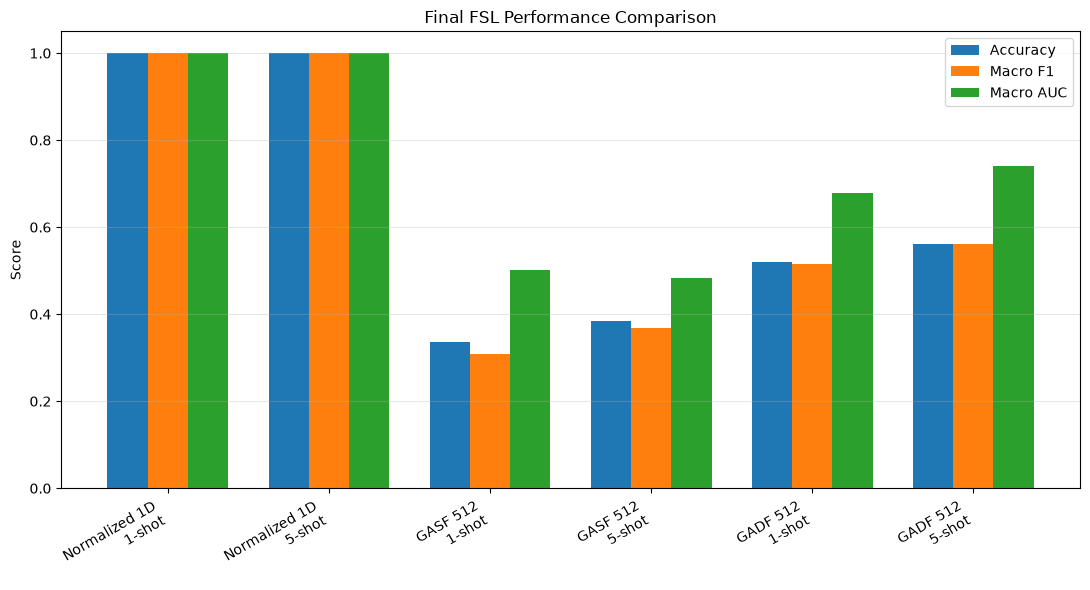

In [39]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

labels = (
    final_comparison["Representation"]
    + "\n"
    + final_comparison["Shot"]
)

x = np.arange(
    len(labels)
)

width = 0.25

ax.bar(
    x - width,
    final_comparison["Accuracy"],
    width,
    label="Accuracy"
)

ax.bar(
    x,
    final_comparison["F1"],
    width,
    label="Macro F1"
)

ax.bar(
    x + width,
    final_comparison["Macro AUC"],
    width,
    label="Macro AUC"
)

ax.set_ylabel("Score")
ax.set_title(
    "Final FSL Performance Comparison"
)

ax.set_xticks(x)
ax.set_xticklabels(
    labels,
    rotation=30,
    ha="right"
)

ax.set_ylim(
    0,
    1.05
)

ax.legend()
ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT / "final_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

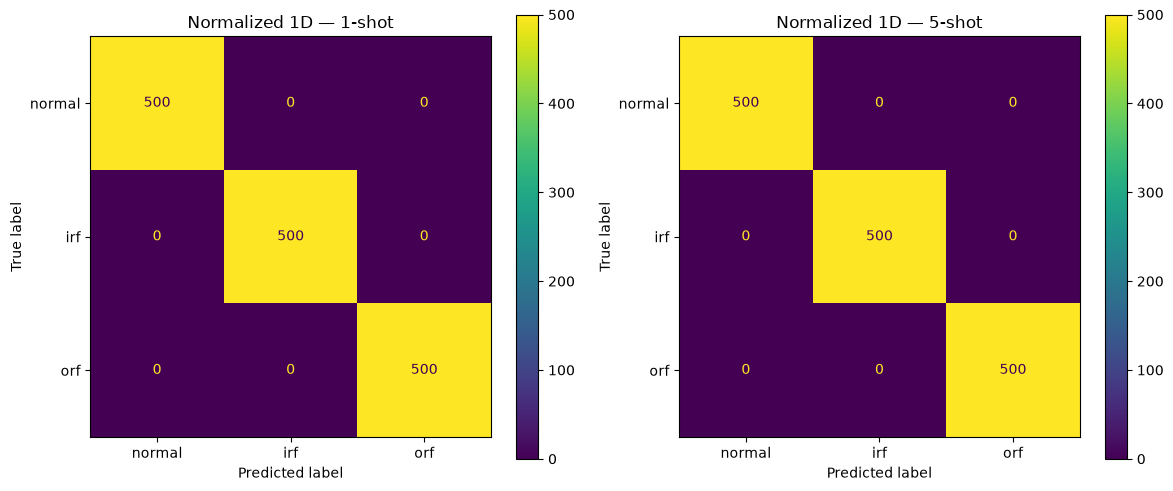

In [40]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

for ax, result, title in [
    (
        axes[0],
        conv1d_1shot,
        "Normalized 1D — 1-shot"
    ),
    (
        axes[1],
        conv1d_5shot,
        "Normalized 1D — 5-shot"
    )
]:

    cm = result["confusion_matrix"]

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    disp.plot(
        ax=ax
    )

    ax.set_title(title)

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT / "normalized_1d_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

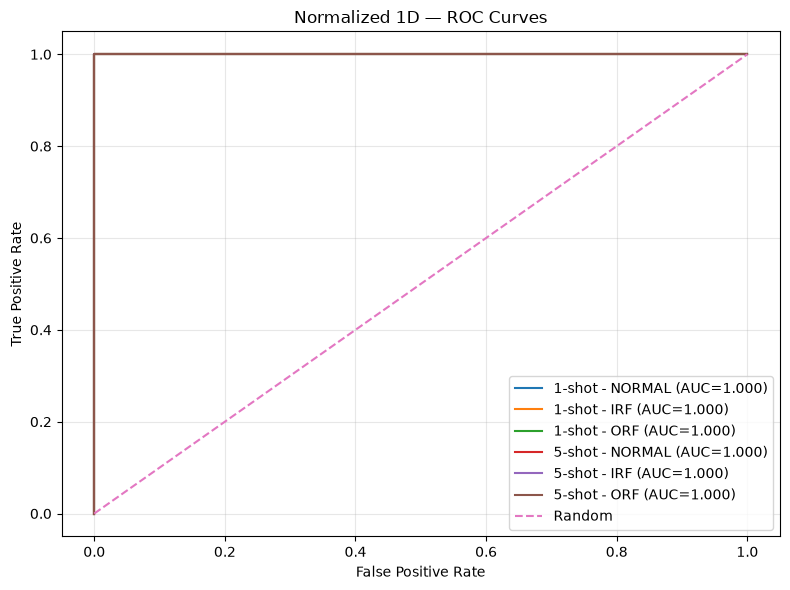

In [41]:
fig, ax = plt.subplots(
    figsize=(8, 6)
)

for result, shot in [
    (conv1d_1shot, "1-shot"),
    (conv1d_5shot, "5-shot")
]:

    for class_id, class_name in enumerate(
        CLASS_NAMES
    ):

        ax.plot(
            result["fpr"][class_id],
            result["tpr"][class_id],
            label=(
                f"{shot} - "
                f"{class_name.upper()} "
                f"(AUC="
                f"{result['roc_auc'][class_id]:.3f})"
            )
        )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

ax.set_xlabel(
    "False Positive Rate"
)

ax.set_ylabel(
    "True Positive Rate"
)

ax.set_title(
    "Normalized 1D — ROC Curves"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT / "normalized_1d_roc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
best = final_comparison.loc[
    final_comparison["Accuracy"].idxmax()
]

print("=" * 70)
print("FINAL BEST CONFIGURATION")
print("=" * 70)

print(
    "Representation:",
    best["Representation"]
)

print(
    "Setting:",
    best["Shot"]
)

print(
    f"Accuracy: {best['Accuracy']:.4f}"
)

print(
    f"F1:       {best['F1']:.4f}"
)

print(
    f"Macro AUC: {best['Macro AUC']:.4f}"
)

FINAL BEST CONFIGURATION
Representation: Normalized 1D
Setting: 1-shot
Accuracy: 1.0000
F1:       1.0000
Macro AUC: 1.0000


In [43]:
print("=" * 80)
print("FINAL PROJECT RESULTS")
print("=" * 80)

print(
    final_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nBest configuration based on Accuracy:")

best = final_comparison.loc[
    final_comparison["Accuracy"].idxmax()
]

print(
    f"{best['Representation']} "
    f"({best['Shot']})"
)

print(
    f"Accuracy = {best['Accuracy']:.4f}"
)

print(
    f"F1 = {best['F1']:.4f}"
)

print(
    f"Macro AUC = {best['Macro AUC']:.4f}"
)

FINAL PROJECT RESULTS
Representation   Shot  Accuracy     F1  Macro AUC
 Normalized 1D 1-shot    1.0000 1.0000     1.0000
 Normalized 1D 5-shot    1.0000 1.0000     1.0000
      GASF 512 1-shot    0.3360 0.3075     0.5007
      GASF 512 5-shot    0.3833 0.3674     0.4835
      GADF 512 1-shot    0.5193 0.5143     0.6791
      GADF 512 5-shot    0.5613 0.5607     0.7400

Best configuration based on Accuracy:
Normalized 1D (1-shot)
Accuracy = 1.0000
F1 = 1.0000
Macro AUC = 1.0000


In [45]:
import pandas as pd
import matplotlib.pyplot as plt

final_results = pd.DataFrame([
    {
        "Representation": "Normalized 1D",
        "1-shot Accuracy": 1.000,
        "1-shot F1": 1.000000,
        "1-shot AUC": 1.000000,
        "5-shot Accuracy": 1.000,
        "5-shot F1": 1.000000,
        "5-shot AUC": 1.000000,
    },

    {
        "Representation": "GASF 224",
        "1-shot Accuracy": 0.350,
        "1-shot F1": 0.330601,
        "1-shot AUC": 0.512503,
        "5-shot Accuracy": 0.360667,
        "5-shot F1": 0.357853,
        "5-shot AUC": 0.525497,
    },

    {
        "Representation": "GADF 224",
        "1-shot Accuracy": 0.464,
        "1-shot F1": 0.467046,
        "1-shot AUC": 0.654311,
        "5-shot Accuracy": 0.518667,
        "5-shot F1": 0.519149,
        "5-shot AUC": 0.727201,
    },

    {
        "Representation": "GASF 512",
        "1-shot Accuracy": 0.3360,
        "1-shot F1": 0.3075,
        "1-shot AUC": 0.5007,
        "5-shot Accuracy": 0.3833,
        "5-shot F1": 0.3674,
        "5-shot AUC": 0.4835,
    },

    {
        "Representation": "GADF 512",
        "1-shot Accuracy": 0.5193,
        "1-shot F1": 0.5143,
        "1-shot AUC": 0.6791,
        "5-shot Accuracy": 0.5613,
        "5-shot F1": 0.5607,
        "5-shot AUC": 0.7400,
    }
])

display(final_results)

,Representation,1-shot Accuracy,1-shot F1,1-shot AUC,5-shot Accuracy,5-shot F1,5-shot AUC
0,Normalized 1D,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000
1,GASF 224,0.3500,0.330601,0.512503,0.360667,0.357853,0.525497
2,GADF 224,0.4640,0.467046,0.654311,0.518667,0.519149,0.727201
3,GASF 512,0.3360,0.307500,0.500700,0.383300,0.367400,0.483500
4,GADF 512,0.5193,0.514300,0.679100,0.561300,0.560700,0.740000


In [46]:
from pathlib import Path

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

final_results.to_csv(
    RESULTS_DIR / "final_comparison.csv",
    index=False
)

print("Saved:", RESULTS_DIR / "final_comparison.csv")

Saved: ..\results\final_comparison.csv


In [47]:
print("=" * 110)
print("FINAL PROJECT RESULTS")
print("=" * 110)

display(
    final_results.style
    .format({
        "1-shot Accuracy": "{:.4f}",
        "1-shot F1": "{:.4f}",
        "1-shot AUC": "{:.4f}",
        "5-shot Accuracy": "{:.4f}",
        "5-shot F1": "{:.4f}",
        "5-shot AUC": "{:.4f}",
    })
)

FINAL PROJECT RESULTS


,Representation,1-shot Accuracy,1-shot F1,1-shot AUC,5-shot Accuracy,5-shot F1,5-shot AUC
0,Normalized 1D,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,GASF 224,0.3500,0.3306,0.5125,0.3607,0.3579,0.5255
2,GADF 224,0.4640,0.4670,0.6543,0.5187,0.5191,0.7272
3,GASF 512,0.3360,0.3075,0.5007,0.3833,0.3674,0.4835
4,GADF 512,0.5193,0.5143,0.6791,0.5613,0.5607,0.7400


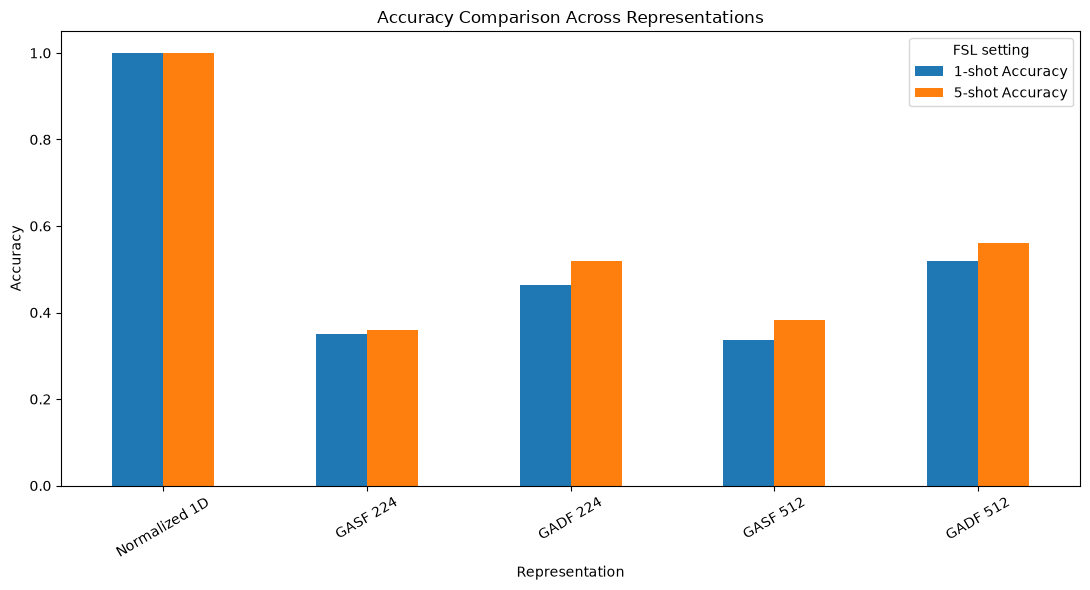

In [48]:
accuracy_df = final_results[
    [
        "Representation",
        "1-shot Accuracy",
        "5-shot Accuracy"
    ]
]

accuracy_plot = accuracy_df.set_index(
    "Representation"
)

accuracy_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Accuracy Comparison Across Representations")
plt.xlabel("Representation")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(title="FSL setting")
plt.tight_layout()
plt.show()

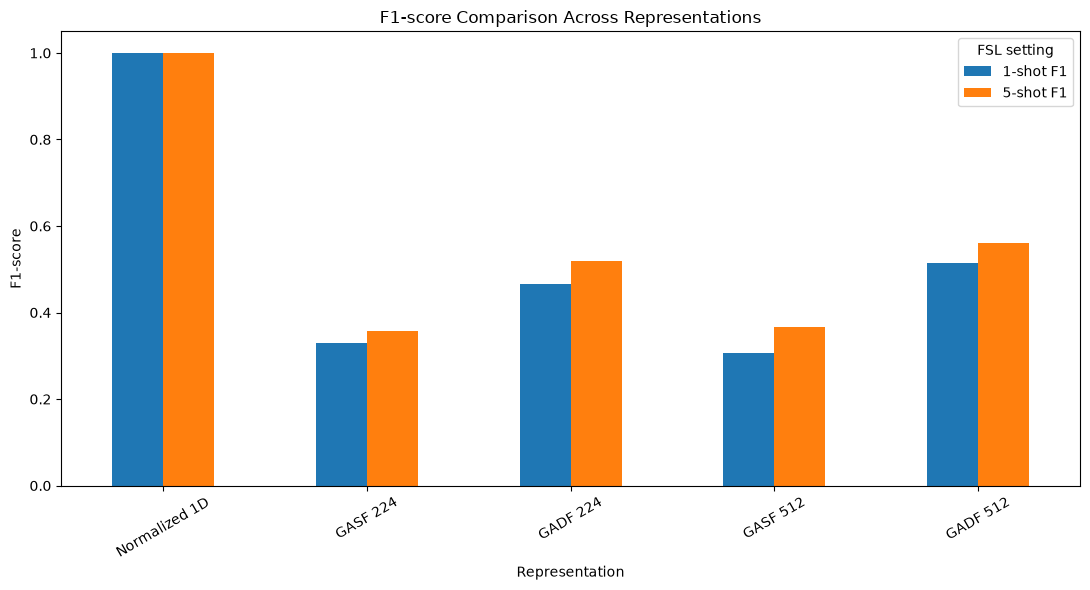

In [49]:
f1_df = final_results[
    [
        "Representation",
        "1-shot F1",
        "5-shot F1"
    ]
]

f1_plot = f1_df.set_index(
    "Representation"
)

f1_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("F1-score Comparison Across Representations")
plt.xlabel("Representation")
plt.ylabel("F1-score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(title="FSL setting")
plt.tight_layout()
plt.show()

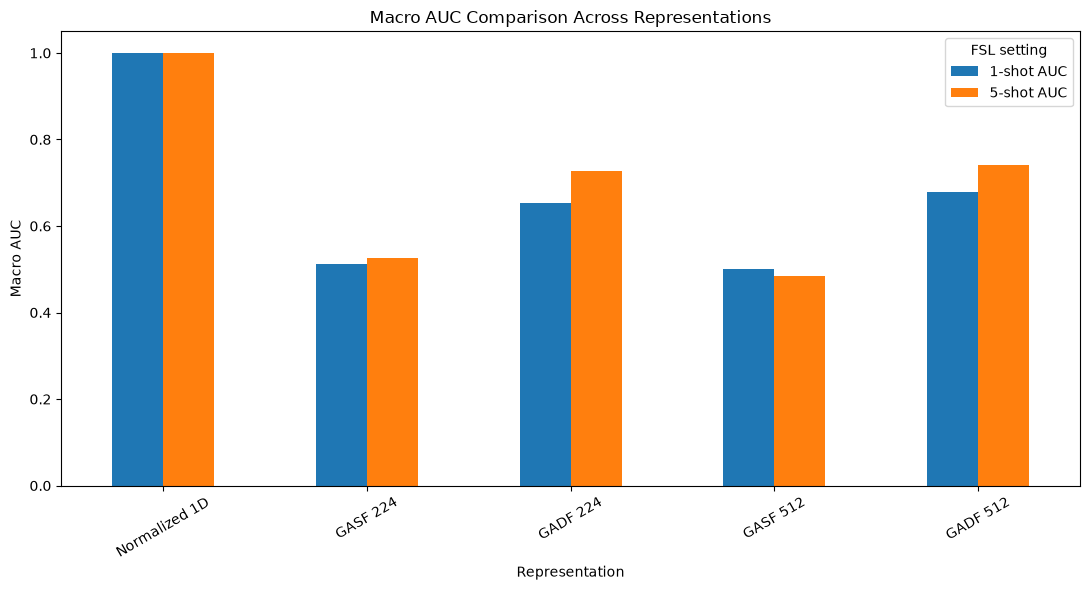

In [50]:
auc_df = final_results[
    [
        "Representation",
        "1-shot AUC",
        "5-shot AUC"
    ]
]

auc_plot = auc_df.set_index(
    "Representation"
)

auc_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Macro AUC Comparison Across Representations")
plt.xlabel("Representation")
plt.ylabel("Macro AUC")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(title="FSL setting")
plt.tight_layout()
plt.show()